# Spotify Hybrid Recommender System
Analysis of the locally prepared Spotify / Last.fm sample.

In [1]:
from pathlib import Path
import json
import sys

root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.recommender import AUDIO, METRICS, Recommender

model = Recommender.load()
catalog = model.catalog
pd.Series({'tracks': len(catalog), 'listeners': model.interactions.shape[1],
           'unique listener-track pairs': model.interactions.nnz})


tracks                          50683
listeners                       19028
unique listener-track pairs    191805
dtype: int64

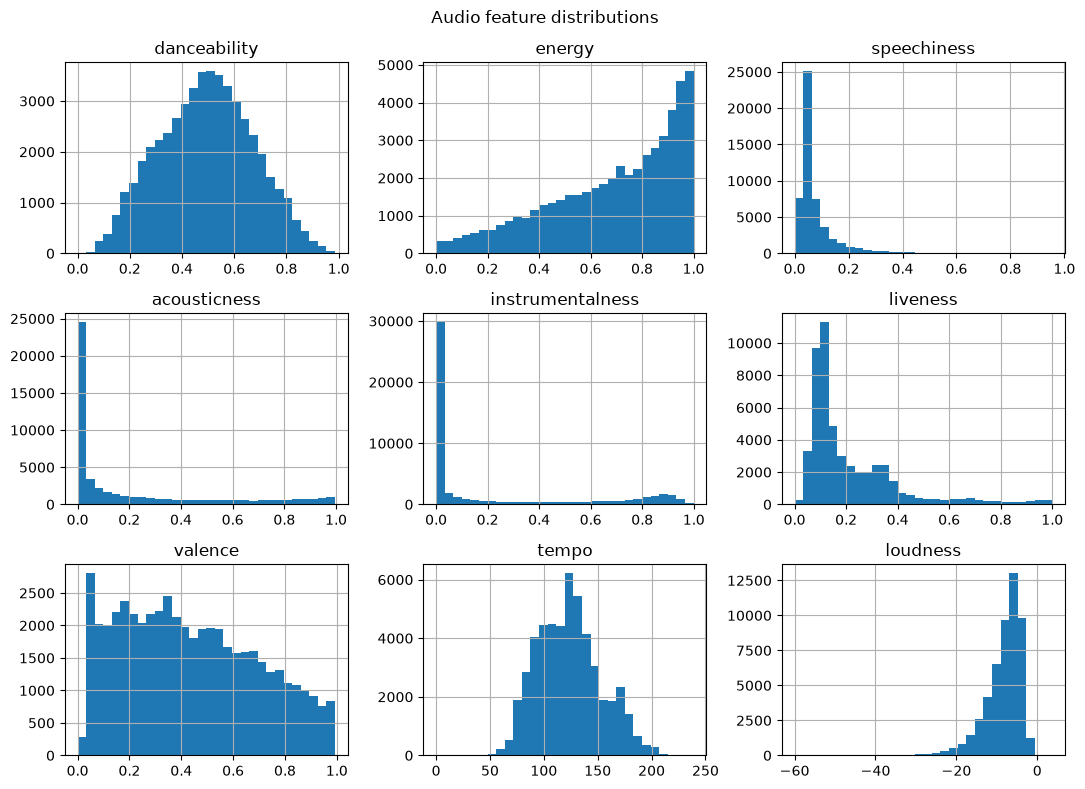

In [2]:
axes = catalog[AUDIO].hist(figsize=(11, 8), bins=30)
plt.suptitle('Audio feature distributions')
plt.tight_layout()
plt.show()

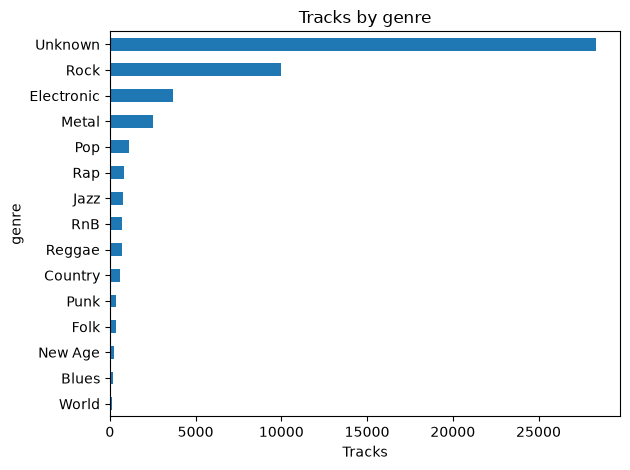

In [3]:
catalog.genre.value_counts().head(15).sort_values().plot.barh(title='Tracks by genre')
plt.xlabel('Tracks')
plt.tight_layout()
plt.show()

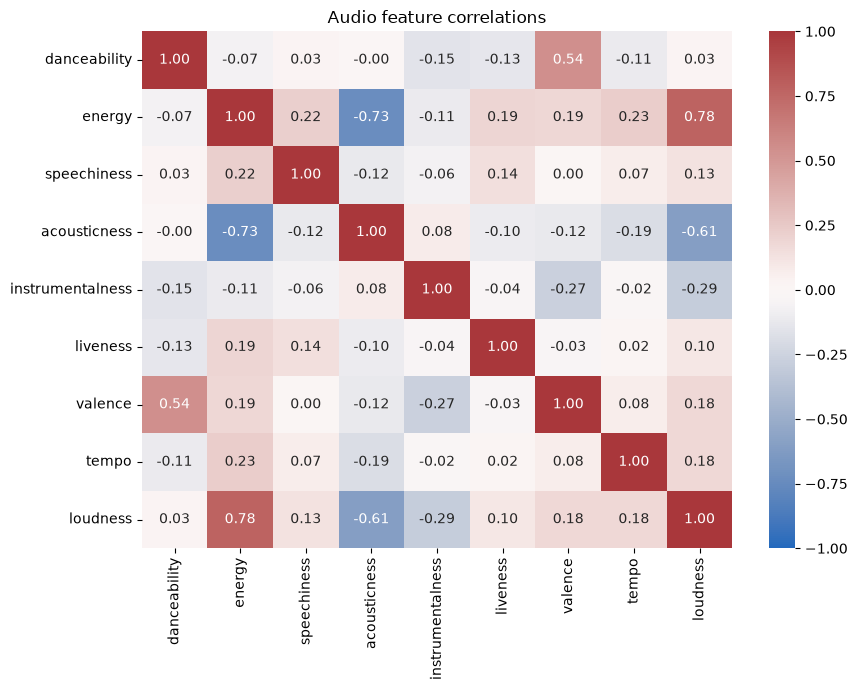

In [4]:
plt.figure(figsize=(9, 7))
sns.heatmap(catalog[AUDIO].corr(), cmap='vlag', vmin=-1, vmax=1, annot=True, fmt='.2f')
plt.title('Audio feature correlations')
plt.tight_layout()
plt.show()

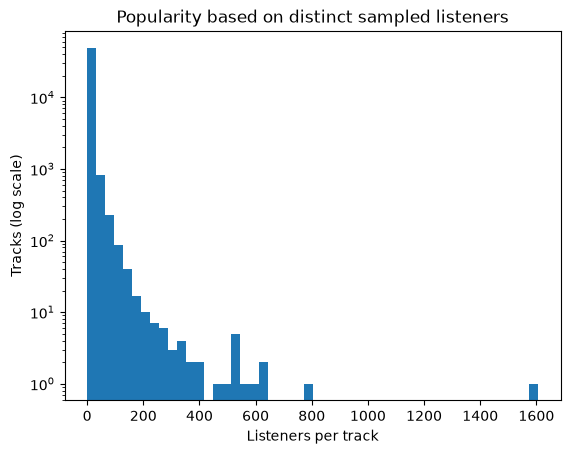

In [5]:
plt.hist(model.popularity, bins=50, log=True)
plt.title('Popularity based on distinct sampled listeners')
plt.xlabel('Listeners per track')
plt.ylabel('Tracks (log scale)')
plt.show()

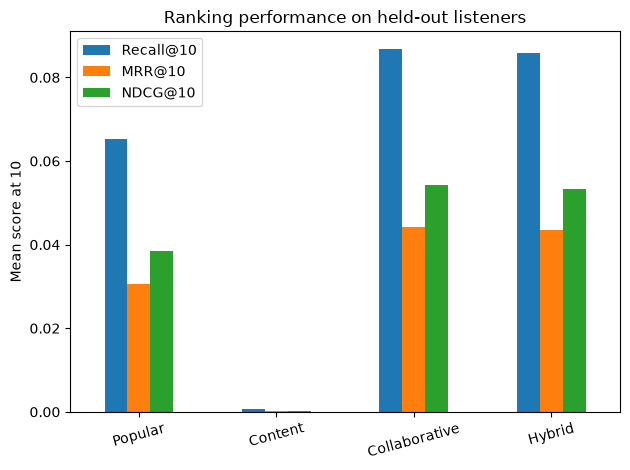

Held-out profiles: 3368


,Recall@10,MRR@10,NDCG@10
Popular,0.065321,0.030476,0.038597
Content,0.000594,0.000134,0.000243
Collaborative,0.086698,0.044275,0.054251
Hybrid,0.085808,0.043426,0.053368


In [6]:
metrics = json.loads(METRICS.read_text(encoding='utf-8'))
scores = pd.DataFrame(metrics['models']).T
scores.plot.bar(rot=15, title='Ranking performance on held-out listeners')
plt.ylabel('Mean score at 10')
plt.tight_layout()
plt.show()
print(f"Held-out profiles: {metrics['test_profiles']}")
scores